In [17]:
%load_ext autoreload
%autoreload 2
import os
import rasterio
import numpy as np
from glob import glob
from tqdm import tqdm
from rasterio.windows import Window
from matplotlib import pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from benchmark import TifSegmentationDataset, benchmark_model
from pathlib import Path

from benchmark import load_terratorch_model, load_geoai_smp_model, predict_terratorch, predict_smp

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
def show_first3_firstfile(cat, win_w=1024, win_h=1024, lo=2, hi=98):
    img_grep = "images/*.tif"
    # pick first file
    paths = sorted(glob(os.path.join("/workspace_bk/piyush/data/sentinal_datastore", cat, "train", img_grep)))
    if not paths:
        print(f"[{cat}] No files found")
        return
    tif_path = paths[-1]

    with rasterio.open(tif_path) as src:
        bands = min(3, src.count)
        if bands < 3:
            print(f"[{cat}] {os.path.basename(tif_path)} has only {src.count} band(s); skipping")
            return
        
        # central crop window to avoid plotting huge rasters
        w = min(win_w, src.width)
        h = min(win_h, src.height)
        col_off = max(0, (src.width - w) // 2)
        row_off = max(0, (src.height - h) // 2)
        window = Window(col_off=col_off, row_off=row_off, width=w, height=h)

        arr = src.read([1, 2, 3], window=window).astype(np.float32)  # (3, H, W)
        if bands > 6: 
            arr = src.read([2, 3, 4], window=window).astype(np.float32)  # (3, H, W)
    img = arr.transpose(1, 2, 0)  # (H, W, 3)

    # robust per-channel stretch for display
    p_lo = np.percentile(img, lo, axis=(0, 1))
    p_hi = np.percentile(img, hi, axis=(0, 1))
    img = np.clip((img - p_lo) / (p_hi - p_lo + 1e-6), 0, 1)

    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    plt.title(f"{cat} | {os.path.basename(tif_path)} | bands 1-3")
    plt.axis("off")
    plt.show()

def compute_mean_std(image_dir, img_grep, scale=10000):
    paths = glob(os.path.join(image_dir, img_grep))
    n_pixels = 0
    channel_sum = None
    channel_sum_sq = None

    for p in tqdm(paths, desc="Computing mean/std"):
        with rasterio.open(p) as src:
            arr = src.read().astype(np.float64)  # (bands, H, W)
            arr /= scale                         # scale raw DN to ~[0,1]

        b, h, w = arr.shape
        if channel_sum is None:
            channel_sum = np.zeros(b, dtype=np.float64)
            channel_sum_sq = np.zeros(b, dtype=np.float64)

        n_pixels += h * w
        flat = arr.reshape(b, -1)
        channel_sum += flat.sum(axis=1)
        channel_sum_sq += (flat ** 2).sum(axis=1)

    mean = channel_sum / n_pixels
    std  = np.sqrt(channel_sum_sq / n_pixels - mean**2)
    return mean.tolist(), std.tolist()

def compute_class_ratio(mask_dir, mask_grep="masks/*.tif", num_classes=None, ignore_index=None, value_map=None):
    """
    Compute per-class pixel ratios over a set of masks.
    """
    paths = glob(os.path.join(mask_dir, mask_grep))
    if not paths:
        print(f"No mask files found in {mask_dir} with {mask_grep}")
        return {}

    total = None
    for p in tqdm(paths, desc="Computing class ratios"):
        with rasterio.open(p) as src:
            arr = src.read(1).astype(np.int64)

        if value_map:
            mapped = np.full(arr.shape, -1, dtype=np.int64)
            for raw_val, cls_id in value_map.items():
                mapped[arr == raw_val] = cls_id
            arr = mapped
            if ignore_index is None:
                ignore_index = -1

        if ignore_index is not None:
            arr = arr[arr != ignore_index]
        if arr.size == 0:
            continue

        if num_classes is None:
            counts = np.bincount(arr.ravel())
        else:
            counts = np.bincount(arr.ravel(), minlength=num_classes)

        if total is None:
            total = counts.astype(np.int64)
        else:
            if counts.size > total.size:
                total = np.pad(total, (0, counts.size - total.size), constant_values=0)
            elif counts.size < total.size:
                counts = np.pad(counts, (0, total.size - counts.size), constant_values=0)
            total += counts

    if total is None or total.sum() == 0:
        return {"counts": [], "ratios": []}

    ratios = (total / total.sum()).tolist()
    return {"counts": total.tolist(), "ratios": ratios}

def create_dl(test_dir, batch_size=4, num_workers=4, dl_params=None):
    images_dir = os.path.join(test_dir, "images")
    masks_dir = os.path.join(test_dir, "masks")

    if dl_params and dl_params.get("normalization") == "imagenet":
        imagenet_means = [0.485, 0.456, 0.406]
        imagenet_stds = [0.229, 0.224, 0.225]
        geoai_scale = 1 / 255.0  # geoai usually reads uint8 or scales to 0-1
        ds = TifSegmentationDataset( images_dir, masks_dir,
        means=imagenet_means, stds=imagenet_stds, constant_scale=geoai_scale)
    elif dl_params and dl_params.get("normalization") == "standardized":
        # terratorch uses constant_scale + channel-wise norm
        means = dl_params["means"] 
        stds = dl_params["stds"]
        scale = dl_params["scale"] if "scale" in dl_params else 1/10000.0
        ds = TifSegmentationDataset( images_dir, masks_dir, means=means, 
        stds=stds, constant_scale=scale)
    else:
        ds = TifSegmentationDataset(images_dir, masks_dir)
    
    dl = DataLoader(ds, batch_size=batch_size, num_workers=num_workers, shuffle=False, pin_memory=True)
    return dl

def count_trainable_params(module: torch.nn.Module | None) -> int:
    if module is None:
        return 0
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


def get_param_breakdown(model) -> tuple[int, int, int]:
    """Return (encoder_params, decoder_params, total_params) for a model/task."""
    base_model = model.model if hasattr(model, "model") else model
    encoder = getattr(base_model, "encoder", None)
    decoder = getattr(base_model, "decoder", None)
    encoder_params = count_trainable_params(encoder)
    decoder_params = count_trainable_params(decoder)
    total_params = count_trainable_params(base_model)
    return encoder_params, decoder_params, total_params

### RBG

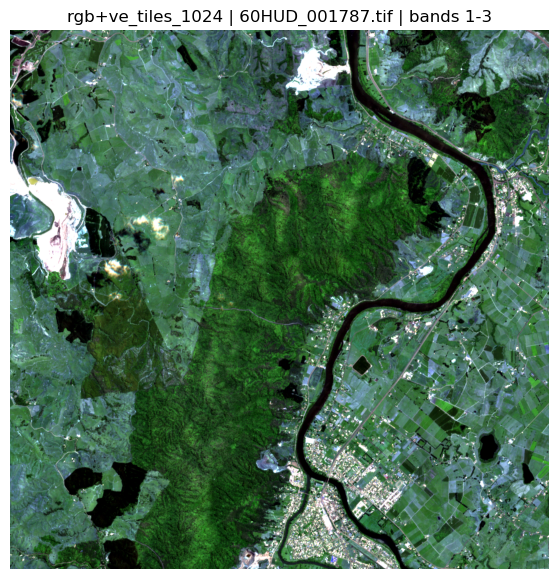

Computed means: [0.10808051888921406, 0.11986660345662084, 0.12866614283181937]
Computed stds : [0.1934757183721109, 0.18732491116331573, 0.19596228303648386]


In [19]:
device = "cuda:0"

num_classes = 2
class_names = ["Not Mine", "Mine"]
test_dir = "/workspace_bk/piyush/data/sentinal_datastore/rgb+ve_tiles_1024/test"

# datacat = ["rgb+ve_tiles_1024", "rgb_nir+ve_tiles_1024", "rgb_irs+ve_tiles_1024"]
# for cat in datacat:
cat = "rgb+ve_tiles_1024"
show_first3_firstfile(cat)
train_data_root = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/train"

# Dataset root contains masks/ folder
# stats = compute_class_ratio(
#     train_data_root,
#     mask_grep="masks/*.tif",
#     num_classes=2
# )
# print(stats)
# means, stds = compute_mean_std(train_data_root, img_grep = "images/*.tif")
means = [0.10808051888921406, 0.11986660345662084, 0.12866614283181937]
stds = [0.1934757183721109, 0.18732491116331573, 0.19596228303648386]
print("Computed means:", means)
print("Computed stds :", stds)

In [ ]:
def visualize_batch_results(model_name, batch_index, batch_data, batch_metrics, means, stds):
    save_dir = "/workspace_bk/piyush/results/cm_seg/rgb+ve_1024/viz_plots"
    # print(f"{model_name} batch index: {batch_index}")
    images_np, masks_np, preds_np = batch_data

    os.makedirs(save_dir, exist_ok=True)

    means_arr = np.asarray(means, dtype=np.float32)[:, None, None]
    stds_arr = np.asarray(stds, dtype=np.float32)[:, None, None]

    confusion_colors = ["#000000", "#648fff", "#dc267f", "#785ef0"]
    confusion_labels = ["TN", "TP", "FN", "FP"]

    iou_mine = batch_metrics.get("IoU_Mine", None)
    recall_mine = batch_metrics.get("Recall_Mine", None)

    safe_model_name = model_name.replace("::", "_").replace("/", "_")

    for i, (pred, mask) in enumerate(zip(preds_np, masks_np)):
        img = images_np[i]

        img_denorm = img * stds_arr + means_arr
        p_lo = np.percentile(img_denorm, 0, axis=(0, 1))
        p_hi = np.percentile(img_denorm, 99.5, axis=(0, 1))
        img_viz = np.clip((img_denorm - p_lo) / (p_hi - p_lo + 1e-6), 0, 1)

        img_vis = np.transpose(img_viz, (1, 2, 0))
        if img_vis.shape[2] > 3:
            img_vis = img_vis[:, :, :3]
        img_vis = np.clip(img_vis, 0, 1)

        mask_bin = np.asarray(mask).astype(np.int64)
        pred_bin = np.asarray(pred).astype(np.int64)

        confusion = np.zeros_like(mask_bin, dtype=np.int64)
        confusion[(mask_bin == 0) & (pred_bin == 1)] = 3
        confusion[(mask_bin == 1) & (pred_bin == 0)] = 2
        confusion[(mask_bin == 1) & (pred_bin == 1)] = 1

        cmap = plt.matplotlib.colors.ListedColormap(confusion_colors)
        norm = plt.matplotlib.colors.BoundaryNorm(np.arange(-0.5, 4.5, 1), cmap.N)

        fig, axs = plt.subplots(1, 2, figsize=(10, 4))
        axs[0].imshow(img_vis)
        axs[1].imshow(confusion, cmap=cmap, norm=norm, interpolation="nearest")

        fig.suptitle(
            f"{model_name} | idx={batch_index} | IoU_Mine={iou_mine:.4f} | Recall_Mine={recall_mine:.4f}",
            fontsize=11
        )

        axs[0].set_title("Image")
        axs[1].set_title("Confusion Plot")

        for ax in axs:
            ax.axis("off")

        handles = [
            plt.matplotlib.patches.Patch(color=color, label=label)
            for color, label in zip(confusion_colors, confusion_labels)
        ]
        axs[1].legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.12),
            ncol=4,
            frameon=False,
        )

        plt.tight_layout()
        out_path = os.path.join(save_dir, f"idx{batch_index}_sample{i}_{safe_model_name}.png")
        plt.savefig(out_path, dpi=200, bbox_inches="tight")
        plt.close(fig)

In [ ]:
from benchmark import get_batch_viz_data


all_results = []

terratorch_save_dir = "/workspace_bk/piyush/runs/terratorch/rgb+ve_1024"
terratorch_ckpts = ["prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step=44700.ckpt",
                    "prithvi_frozen_unet_lr1e-4_ce_.25.75_v1/best-epoch=48-val_loss=0.0000.ckpt", 
                    "prithvi_frozen_unet_lr1e-4_ce_.25.75_v1/last.ckpt",
                    "prithvi_lr1e-5_unet_lr1e-4_ce_.25.75/checkpoints/epoch=99-step=89400.ckpt",
                    "prithvi_lr1e-5unfreeze10_unet_lr1e-4_ce_.25.75/best-epoch=21-val_loss=0.0000.ckpt",
                    "prithvi_lr1e-5unfreeze10_unet_lr1e-4_ce_.25.75/last.ckpt"]  # List of Terratorch checkpoint paths
model_names = ["frozen_unet_v0_last", "frozen_unet_v1_best", "frozen_unet_v1_last", 
               "unfreeze0_unet_last", "unfreeze10_unet_best", "unfreeze10_unet_last"]  # Corresponding model names for display

output_dir = "/workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200"
geoai_dirs = [d for d in Path(output_dir).glob("*") if d.is_dir()]   

dl_geoai = create_dl(test_dir, batch_size=1, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})    
viz_idxs = [15, 64, 74, 96]
# ---- Benchmark geoai / smp models ----
for model_dir in geoai_dirs:
    model_name = f"geoai::{os.path.basename(model_dir)}"
    print(f"\nLoading geoai model: {model_dir}")
    try:
        model = load_geoai_smp_model(model_dir, num_channel=3, device=device)
        # metrics, viz_idx, viz_batch_data, viz_batch_metrics = benchmark_model(
        #     model_name, predict_smp, model,
        #     dl_geoai, num_classes, device, class_names, viz_idx=7
        # )
        # metrics["checkpoint"] = model_dir
        # all_results.append(metrics)
        encoder_params, decoder_params, total_params = get_param_breakdown(model)
        for viz_idx in viz_idxs:
            viz_batch_data, viz_batch_metrics = get_batch_viz_data(
                model_name, predict_smp, model,
                dl_geoai, num_classes, device, class_names, viz_idx=viz_idx
            )
            # print(model_name, encoder_params, decoder_params, total_params)
            # print(viz_batch_metrics)
            visualize_batch_results(model_name, viz_idx, viz_batch_data, viz_batch_metrics, means, stds)
        del model
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}")

dl_terratorch = create_dl(test_dir, batch_size=1, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})
for ckpt_path, model_name in zip(terratorch_ckpts, model_names):
        ckpt_path = os.path.join(terratorch_save_dir, ckpt_path)
        model_name = f"terratorch::{model_name}"
        print(f"\nLoading terratorch model: {ckpt_path}")
        try:
            task = load_terratorch_model(ckpt_path, device)
            encoder_params, decoder_params, total_params = get_param_breakdown(task)
            # metrics, viz_idx, viz_batch_data, viz_batch_metrics = benchmark_model(
            #     model_name, predict_terratorch, task,
            #     dl_terratorch, num_classes, device, class_names, viz_idx=7
            # )
            # metrics["checkpoint"] = ckpt_path
            # all_results.append(metrics)
            print(model_name, encoder_params, decoder_params, total_params)
            for viz_idx in viz_idxs:
                viz_batch_data, viz_batch_metrics = get_batch_viz_data(
                    model_name, predict_terratorch, task,
                    dl_terratorch, num_classes, device, class_names, viz_idx=viz_idx
                )
                # print(model_name, encoder_params, decoder_params, total_params)
                # print(viz_batch_metrics)
                visualize_batch_results(model_name, viz_idx, viz_batch_data, viz_batch_metrics, means, stds)
            del task
            torch.cuda.empty_cache()
        except Exception as e:
            print(f"  ✗ Failed: {e}")


Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/deeplabv3plus_mit_b1


geoai::deeplabv3plus_mit_b1 13151424 1152528 14304466
geoai::deeplabv3plus_mit_b1 batch index: 15


geoai::deeplabv3plus_mit_b1 13151424 1152528 14304466
geoai::deeplabv3plus_mit_b1 batch index: 64


geoai::deeplabv3plus_mit_b1 13151424 1152528 14304466
geoai::deeplabv3plus_mit_b1 batch index: 74


geoai::deeplabv3plus_mit_b1 13151424 1152528 14304466
geoai::deeplabv3plus_mit_b1 batch index: 96

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/deeplabv3plus_resnet50


geoai::deeplabv3plus_resnet50 23508032 3169296 26677842
geoai::deeplabv3plus_resnet50 batch index: 15


... (20 outputs left out)

geoai::segformer_efficientnet-b3 10696232 493312 11190058
geoai::segformer_efficientnet-b3 batch index: 64


geoai::segformer_efficientnet-b3 10696232 493312 11190058
geoai::segformer_efficientnet-b3 batch index: 74


geoai::segformer_efficientnet-b3 10696232 493312 11190058
geoai::segformer_efficientnet-b3 batch index: 96

Loading geoai model: /workspace_bk/piyush/runs/geoai_smp/rgb+ve_1024_lr1e-4_epochs200/deeplabv3plus_efficientnet-b3


  geoai::deeplabv3plus_efficientnet-b3 (viz):   0%|          | 0/258 [00:00<?, ?it/s]

In [ ]:
import pandas as pd

df = pd.DataFrame(all_results)
# Reorder columns for readability
col_order = [
    "model", "mIoU", "mF1", "Overall_Accuracy",
    "IoU_Not Mine", "IoU_Mine", "F1_Not Mine", "F1_Mine",
    "Precision_Not Mine", "Precision_Mine", "Recall_Not Mine", "Recall_Mine",
    "mPrecision", "mRecall", "checkpoint", "encoder_params", "decoder_params", "total_params"
]
col_order = [c for c in col_order if c in df.columns]
df = df[col_order]

print("\n" + "=" * 100)
print("BENCHMARK RESULTS")
print("=" * 100)
# Print nicely with pandas
with pd.option_context("display.max_columns", None, "display.width", 200, "display.float_format", "{:.4f}".format):
    print(df.to_string(index=False))
print("=" * 100)
# df.to_csv("benchmark_results.csv", index=False)

### Multipsectral

In [ ]:
device = "cuda:0"

num_classes = 2
class_names = ["Not Mine", "Mine"]
all_results = []
prithvi_base_dir = "/workspace_bk/piyush/runs/terratorch"
geoai_base_dir = "/workspace_bk/piyush/runs/geoai_smp"

datacat = ["rgb+ve_tiles_1024", "rgb_nir+ve_tiles_1024", "rgb_irs+ve_tiles_1024", "all_bands+ve_tiles_1024"]
prithvi_ckpts = ["rgb+ve_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75_v0/checkpoints/epoch=49-step=44700.ckpt",
                 "rgb_nir+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=11-val_loss=0.0000.ckpt",
                 "rgb_irs+ve_tiles_1024/prithvi_frozen_unet_lr1e-4_ce_.25.75/best-epoch=14-val_loss=0.0000.ckpt",
                 ""]
segformer_ckpt_dirs = ["rgb+ve_1024_lr1e-4_epochs200/segformer_mit_b1",
                   "nc4_bs4_lr1e-4_epochs200/segformer_mit_b1",
                   "nc6_bs4_lr1e-4_epochs200/segformer_mit_b1",
                   "nc15_bs2_lr1e-4_epochs200/segformer_mit_b1"]
for cat, prithvi_ckpt, segformer_ckpt_dir in zip(datacat, prithvi_ckpts, segformer_ckpt_dirs):
    prithvi_ckpt_path = os.path.join(prithvi_base_dir, prithvi_ckpt)
    segformer_ckpt_path = os.path.join(geoai_base_dir, segformer_ckpt_dir)
    show_first3_firstfile(cat)
    train_data_root = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/train"
    test_dir = f"/workspace_bk/piyush/data/sentinal_datastore/{cat}/test"
    img_grep = "images/*.tif"
    means, stds = compute_mean_std(train_data_root, img_grep)
    print("Computed means:", means)
    print("Computed stds :", stds)

    num_channel = len(means)
    print(f"Number of channels for {cat}: {num_channel}")
    dataloader = create_dl(test_dir, batch_size=2, num_workers=4, dl_params={"normalization": "standardized", "means": means, "stds": stds})

    print(f"\nLoading geoai model: {segformer_ckpt_path}")
    model_name = f"segformer::{cat}"
    try:
        model = load_geoai_smp_model(segformer_ckpt_path, num_channel, device)
        metrics = benchmark_model(
            model_name, predict_smp, model,
            dataloader, num_classes, device, class_names,
        )
        metrics["checkpoint"] = segformer_ckpt_path
        all_results.append(metrics)
        del model
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}") 

    print(f"\nLoading terratorch model: {prithvi_ckpt_path}")
    model_name = f"prithvi::{cat}"
    try:
        task = load_terratorch_model(prithvi_ckpt_path, device)
        metrics = benchmark_model(
            model_name, predict_terratorch, task,
            dataloader, num_classes, device, class_names,
        )
        metrics["checkpoint"] = prithvi_ckpt_path
        all_results.append(metrics)
        del task
        torch.cuda.empty_cache()
    except Exception as e:
        print(f"  ✗ Failed: {e}")

In [ ]:
import pandas as pd

df = pd.DataFrame(all_results)
# Reorder columns for readability
col_order = [
    "model", "mIoU", "mF1", "Overall_Accuracy",
    "IoU_Not Mine", "IoU_Mine", "F1_Not Mine", "F1_Mine",
    "Precision_Not Mine", "Precision_Mine", "Recall_Not Mine", "Recall_Mine",
    "mPrecision", "mRecall", "checkpoint",
]
col_order = [c for c in col_order if c in df.columns]
df = df[col_order]

print("\n" + "=" * 100)
print("BENCHMARK RESULTS")
print("=" * 100)
# Print nicely with pandas
with pd.option_context("display.max_columns", None, "display.width", 200, "display.float_format", "{:.4f}".format):
    print(df.to_string(index=False))
print("=" * 100)